# 04 - Pollutants, episodes and the CAI, 2015-2025

**Questions:** how do the six pollutants move together, how often do multi-day PM2.5 episodes happen and has that changed, which high-PM10 days look dominated by coarse dust, and what does the official Korean air quality index (CAI) say about the period?

**Data:** the official hourly readings of the 25 urban stations, 2015-2025 (notebook 07).

## 1. Imports

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from seoul_air import config
from seoul_air import cai
from seoul_air.episodes import find_episodes
from seoul_air.report import save_key_figures
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

In [2]:
hourly = pd.read_parquet(config.DATA_PROCESSED / "air_hourly_2015_2025.parquet")
daily = pd.read_parquet(config.DATA_PROCESSED / "air_daily_2015_2025.parquet")
pollutants = list(config.POLLUTANTS)
city = daily.groupby("date")[pollutants].mean()

## 2. Correlation between pollutants

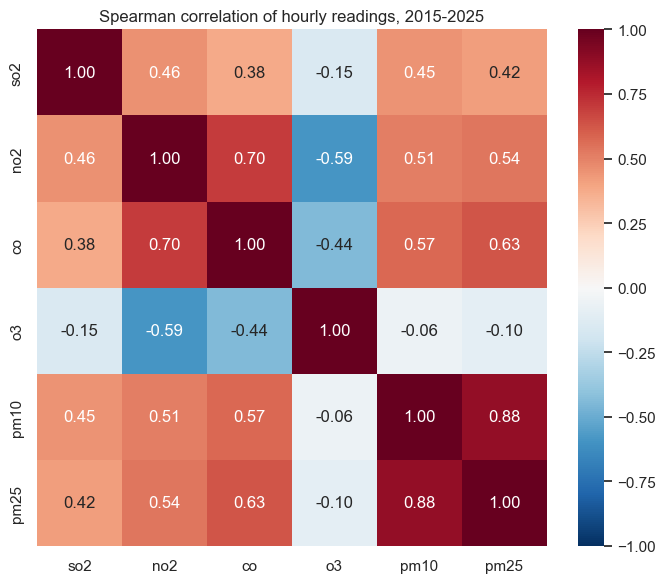

,so2,no2,co,o3,pm10,pm25
so2,1.00,0.46,0.38,-0.15,0.45,0.42
no2,0.46,1.00,0.70,-0.59,0.51,0.54
co,0.38,0.70,1.00,-0.44,0.57,0.63
o3,-0.15,-0.59,-0.44,1.00,-0.06,-0.10
pm10,0.45,0.51,0.57,-0.06,1.00,0.88
pm25,0.42,0.54,0.63,-0.10,0.88,1.00


In [3]:
corr = hourly[pollutants].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation of hourly readings, 2015-2025")
fig.tight_layout()
fig.savefig(config.FIGURES / "04_pollutant_correlation.png", dpi=120)
plt.show()
corr.round(2)

**Interpretation.** PM2.5 and PM10 are strongly correlated (Spearman 0.88), and both correlate moderately with CO (0.63 and 0.57) and NO2 (0.54 and 0.51), gases commonly associated with combustion. O3 is negatively correlated with NO2 (-0.59) and CO (-0.44) and almost uncorrelated with particulate matter (-0.10 with PM2.5). These are correlations between readings; they do not show a shared source.

## 3. Ozone and particulate matter peak in different seasons

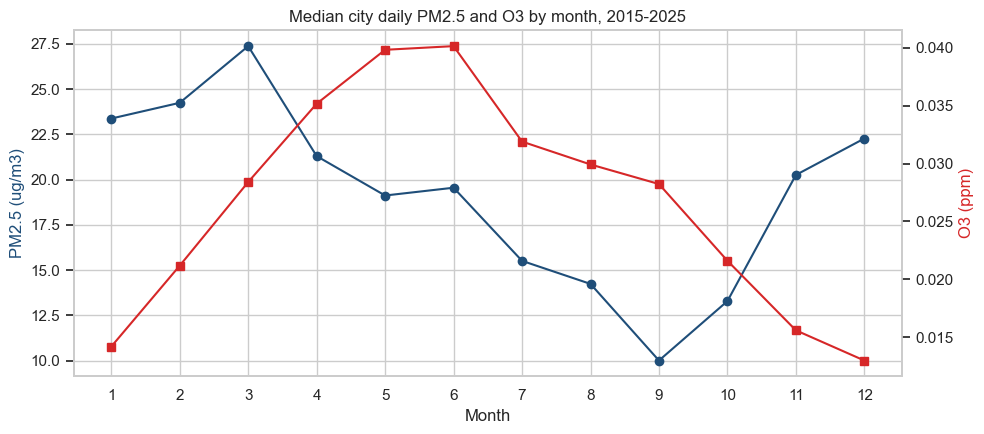

PM2.5 highest month: 3 | O3 highest month: 6


In [4]:
monthly = city.groupby(city.index.month)[["pm25", "o3"]].median()
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(monthly.index, monthly["pm25"], marker="o", color="#1f4e79", label="PM2.5")
ax1.set_ylabel("PM2.5 (ug/m3)", color="#1f4e79")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["o3"], marker="s", color="#d62728", label="O3")
ax2.set_ylabel("O3 (ppm)", color="#d62728")
ax2.grid(False)
ax1.set_xticks(range(1, 13))
ax1.set_xlabel("Month")
ax1.set_title("Median city daily PM2.5 and O3 by month, 2015-2025")
fig.tight_layout()
fig.savefig(config.FIGURES / "04_pm25_vs_o3_season.png", dpi=120)
plt.show()
print("PM2.5 highest month:", monthly["pm25"].idxmax(), "| O3 highest month:", monthly["o3"].idxmax())

**Interpretation.** Particulate matter and ozone peak in different seasons: the city median PM2.5 is highest in March and O3 in June. The highest readings of the two pollutants fall in different parts of the year, so a single indicator does not describe air quality across the seasons.

## 4. Multi-day PM2.5 episodes

An **episode** is a run of at least 2 consecutive days in which the city-wide daily PM2.5 mean is graded Bad or worse (rounded mean above 35 ug/m3). This is a project definition, not an official alert record. Days without a city value are not counted as Bad, so a gap ends a run.

In [5]:
runs = find_episodes(city["pm25"])
n_valid = int(city["pm25"].notna().sum())
n_bad = int(runs["days"].sum())
episodes = runs[runs["days"] >= 2].sort_values("days", ascending=False).reset_index(drop=True)
print(f"Bad-or-worse city days: {n_bad} of {n_valid} valid days ({100 * n_bad / n_valid:.1f}%)")
print("Episodes of 2+ days:", len(episodes), "| runs next to a gap:", int((runs["gap_before"] | runs["gap_after"]).sum()))
episodes.head(10).round(1)

Bad-or-worse city days: 508 of 4018 valid days (12.6%)
Episodes of 2+ days: 134 | runs next to a gap: 0


,start,end,days,peak_pm25,mean_pm25,gap_before,gap_after
0,2019-02-27,2019-03-07,9,135.3,82.6,False,False
1,2018-03-23,2018-03-30,8,99.0,60.5,False,False
2,2016-03-17,2016-03-23,7,47.7,42.5,False,False
3,2016-05-25,2016-05-31,7,70.6,52.4,False,False
4,2019-02-20,2019-02-25,6,62.2,52.9,False,False
5,2018-01-13,2018-01-18,6,87.8,62.1,False,False
6,2020-11-12,2020-11-17,6,51.7,45.5,False,False
7,2025-03-20,2025-03-25,6,59.9,48.9,False,False
8,2021-03-10,2021-03-15,6,89.1,59.9,False,False
9,2017-03-25,2017-03-30,6,57.0,45.9,False,False


Episodes by season of their start: {'Winter': 65, 'Spring': 43, 'Summer': 10, 'Autumn': 16}


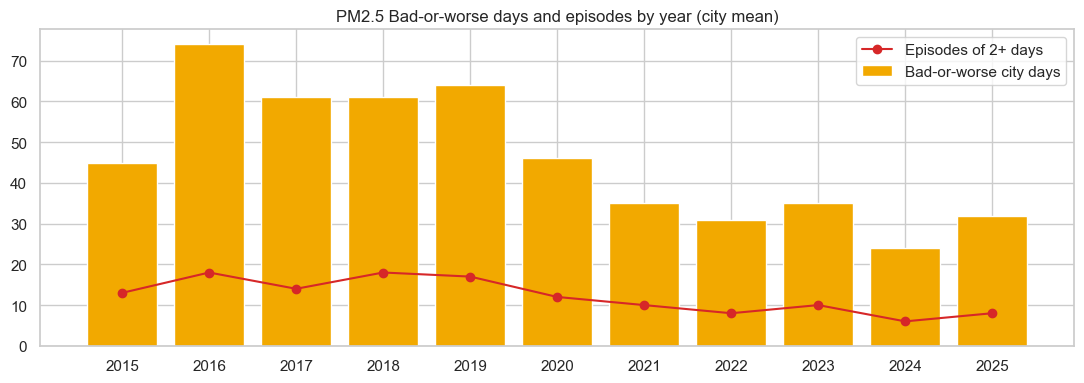

start,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
bad_or_worse_days,45,74,61,61,64,46,35,31,35,24,32
episodes_2plus_days,13,18,14,18,17,12,10,8,10,6,8
longest_episode_days,5,7,6,8,9,6,6,4,5,4,6


In [6]:
by_year = pd.DataFrame({
    "bad_or_worse_days": runs.groupby(runs["start"].dt.year)["days"].sum(),
    "episodes_2plus_days": episodes.groupby(episodes["start"].dt.year).size(),
    "longest_episode_days": episodes.groupby(episodes["start"].dt.year)["days"].max(),
}).reindex(range(2015, 2026)).fillna(0).astype(int)
season = episodes["start"].dt.month.map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
                                         6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"})
print("Episodes by season of their start:", season.value_counts().reindex(["Winter", "Spring", "Summer", "Autumn"]).fillna(0).astype(int).to_dict())
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(by_year.index, by_year["bad_or_worse_days"], color="#f2a900", label="Bad-or-worse city days")
ax.plot(by_year.index, by_year["episodes_2plus_days"], marker="o", color="#d62728", label="Episodes of 2+ days")
ax.set_xticks(by_year.index)
ax.set_title("PM2.5 Bad-or-worse days and episodes by year (city mean)")
ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURES / "04_episodes_by_year.png", dpi=120)
plt.show()
by_year.T

**Interpretation.** The city-wide daily PM2.5 was Bad or worse on 508 of the 4,018 days (12.6%), forming 134 episodes of two days or more; the longest lasted 9 days (2019-02-27 to 2019-03-07, peak 135.3 ug/m3). Episodes start mostly in winter (65) and spring (43), rarely in summer (10). They have become less frequent: from 74 Bad-or-worse days and 18 episodes in 2016 to 24 days and 6 episodes in 2024 (32 and 8 in 2025). The extended data has no day without a city value, so no run is cut by a gap.

## 5. Coarse-dust days

When PM10 is high but the PM2.5 / PM10 ratio is low, coarse particles dominate, which is typical of dust events such as spring yellow dust (hwangsa). A **coarse-dust day** here has a city PM10 mean graded Bad or worse (above 80 ug/m3) and a PM2.5 / PM10 ratio below 0.4: a rule of thumb, not an official yellow-dust record.

In [7]:
city["ratio"] = city["pm25"] / city["pm10"]
high_pm10 = city["pm10"].round() > 80
coarse = city[high_pm10 & (city["ratio"] < 0.4)]
print(f"Days with city PM10 Bad or worse: {int(high_pm10.sum())}; of these, coarse-dust days: {len(coarse)}")
print("Coarse-dust days by month:", coarse.index.month.value_counts().sort_index().to_dict())
print("Coarse-dust days by year:", coarse.index.year.value_counts().sort_index().to_dict())
coarse[["pm10", "pm25", "ratio"]].sort_values("pm10", ascending=False).head(8).round(2)

Days with city PM10 Bad or worse: 195; of these, coarse-dust days: 64
Coarse-dust days by month: {1: 2, 2: 6, 3: 20, 4: 16, 5: 13, 10: 2, 11: 3, 12: 2}
Coarse-dust days by year: {2015: 10, 2016: 5, 2017: 7, 2018: 4, 2019: 6, 2020: 2, 2021: 8, 2022: 3, 2023: 10, 2024: 7, 2025: 2}


,pm10,pm25,ratio
date,,,
2015-02-23,568.67,66.05,0.12
2021-05-08,440.92,81.58,0.19
2021-05-07,354.22,73.94,0.21
2021-03-29,285.30,52.23,0.18
2023-04-12,260.95,29.24,0.11
2015-02-22,248.47,32.70,0.13
2024-03-29,230.60,41.02,0.18
2016-04-23,198.29,41.88,0.21


**Interpretation.** Of the 195 days with a city PM10 mean graded Bad or worse, 64 meet the coarse-dust rule, mostly in March (20), April (16) and May (13). The strongest were 2015-02-23 (PM10 568.67 ug/m3, ratio 0.12) and 2021-05-08 (440.92). Their number varies from year to year (from 2 to 10) without a clear direction. These days are consistent with dust events; confirming yellow dust would require the KMA dust records.

## 6. The Comprehensive Air-quality Index (CAI)

The CAI is the index that AirKorea and Seoul publish to the public (see `src/seoul_air/cai.py` for the definition and sources). Each pollutant gets a sub-index of 0-500 from its concentration: gases from their hourly value, PM10 and PM2.5 from a 24-hour **predicted** moving average that weights the last 4 hours as much as the last 12. The CAI is the highest sub-index, plus 50 points when two pollutants are Unhealthy or worse and 75 when three or more are.

The CAI is hourly. A day is described here by its **highest** hourly CAI, the value a resident would have seen at the worst moment of the day; this is a project summary, not an official daily statistic.

Station-hours with a CAI: 2383412 of 2410800 | with the bonus for several Unhealthy pollutants: 92835


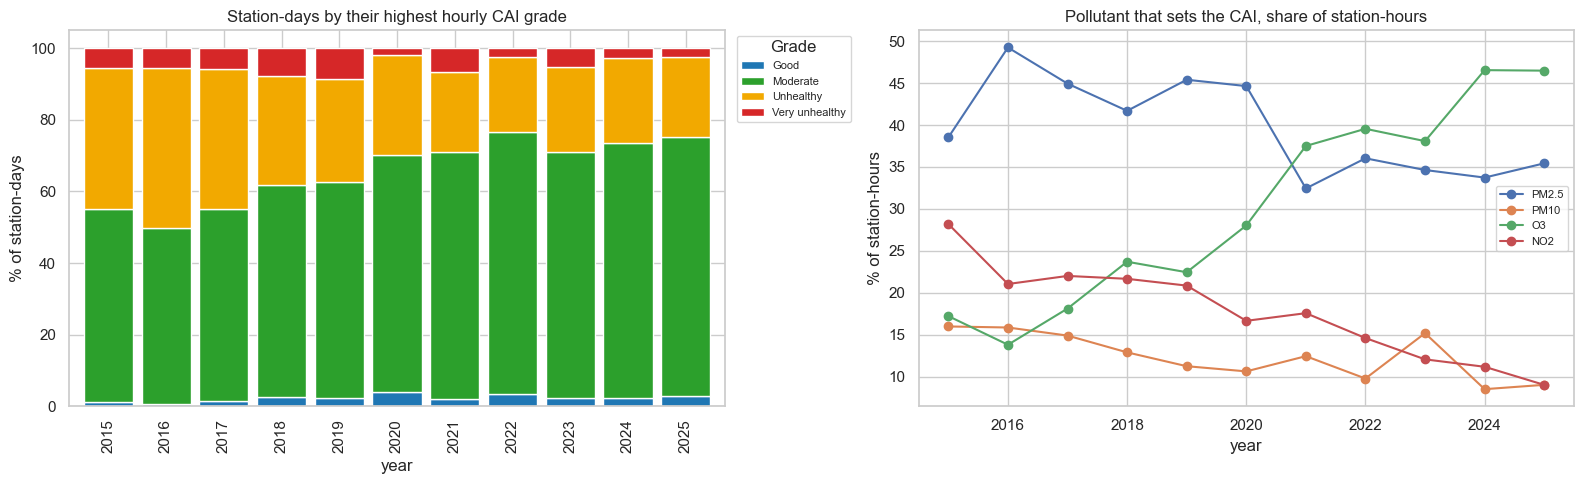

Grade of the worst hour, % of station-days:
grade  Good  Moderate  Unhealthy  Very unhealthy
year                                            
2015    1.1      54.1       39.5             5.4
2016    0.6      49.1       44.9             5.4
2017    1.4      53.7       39.1             5.9
2018    2.5      59.3       30.5             7.6
2019    2.3      60.5       28.7             8.5
2020    4.0      66.3       27.9             1.8
2021    2.0      69.0       22.5             6.5
2022    3.5      73.2       20.9             2.3
2023    2.4      68.6       24.0             5.1
2024    2.4      71.2       23.8             2.7
2025    2.7      72.5       22.3             2.4


main_pollutant,pm25,pm10,o3,no2,co,so2
year,,,,,,
2015,38.5,16.0,17.2,28.2,0.0,0.0
2016,49.2,15.9,13.8,21.1,0.0,0.0
2017,44.9,14.9,18.1,22.0,0.0,0.0
2018,41.7,12.9,23.7,21.7,0.0,0.0
2019,45.4,11.3,22.5,20.9,0.0,0.0
2020,44.6,10.6,28.0,16.7,0.0,0.0
2021,32.4,12.5,37.5,17.6,0.0,0.0
2022,36.0,9.8,39.6,14.6,0.0,0.0
2023,34.6,15.2,38.1,12.1,0.0,0.0


In [8]:
frames = []
for code, rows in hourly.groupby("station_code"):
    rows = rows.sort_values("datetime").reset_index(drop=True)
    result = cai.station_cai(rows[pollutants])
    frames.append(result[["cai", "grade", "main_pollutant", "unhealthy_pollutants"]].assign(
        datetime=rows["datetime"], station_code=code))
cai_hourly = pd.concat(frames, ignore_index=True)
cai_hourly["year"] = cai_hourly["datetime"].dt.year
print("Station-hours with a CAI:", int(cai_hourly["cai"].notna().sum()), "of", len(cai_hourly),
      "| with the bonus for several Unhealthy pollutants:", int((cai_hourly["unhealthy_pollutants"] >= 2).sum()))
cai_day = (cai_hourly.assign(date=cai_hourly["datetime"].dt.normalize())
           .groupby(["station_code", "date"])["cai"].max().reset_index())
cai_day["grade"] = cai.grade(cai_day["cai"].to_numpy()).to_numpy()
cai_day["year"] = cai_day["date"].dt.year
grade_by_year = pd.crosstab(cai_day["year"], cai_day["grade"], normalize="index").mul(100)[cai.GRADES]
main_by_year = (cai_hourly.dropna(subset=["cai"]).groupby("year")["main_pollutant"]
                .value_counts(normalize=True).mul(100).unstack()
                .reindex(columns=["pm25", "pm10", "o3", "no2", "co", "so2"], fill_value=0).fillna(0))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
colors = {"Good": "#1f77b4", "Moderate": "#2ca02c", "Unhealthy": "#f2a900", "Very unhealthy": "#d62728"}
grade_by_year.plot(kind="bar", stacked=True, ax=axes[0], color=[colors[g] for g in cai.GRADES], width=0.85)
axes[0].set_title("Station-days by their highest hourly CAI grade")
axes[0].set_ylabel("% of station-days")
axes[0].legend(title="Grade", fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
main_by_year[["pm25", "pm10", "o3", "no2"]].plot(ax=axes[1], marker="o")
axes[1].set_title("Pollutant that sets the CAI, share of station-hours")
axes[1].set_ylabel("% of station-hours")
axes[1].legend(["PM2.5", "PM10", "O3", "NO2"], fontsize=8)
fig.tight_layout()
fig.savefig(config.FIGURES / "04_cai.png", dpi=120)
plt.show()
print("Grade of the worst hour, % of station-days:")
print(grade_by_year.round(1).to_string())
main_by_year.round(1)

**Interpretation.** A CAI could be computed for 2,383,412 of the 2,410,800 station-hours, and 92,835 hours carry the bonus for several Unhealthy pollutants. The worst hour of a station-day was Unhealthy on 39.5% and Very unhealthy on 5.4% of station-days in 2015, against 22.3% and 2.4% in 2025. Few days are Good at their worst hour (between 0.6% and 4.0%), because some pollutant almost always rises above the Good band at some hour. **The pollutant that sets the index has changed.** PM2.5 sets it in 49.2% of station-hours in 2016 and 35.4% in 2025, NO2 falls from 28.2% to 9.0%, and ozone rises from 17.2% in 2015 to 46.5% in 2024 and 2025, now the most frequent. This daily summary takes the highest hourly CAI; it is not an official daily statistic.

## 7. Key figures

In [9]:
unhealthy_or_worse = grade_by_year["Unhealthy"] + grade_by_year["Very unhealthy"]
save_key_figures("04", {
    "bad_city_days": n_bad, "valid_city_days": n_valid, "episodes_2plus_days": len(episodes),
    "episodes_by_year": by_year["episodes_2plus_days"].to_dict(),
    "bad_days_by_year": by_year["bad_or_worse_days"].to_dict(),
    "cai_unhealthy_or_worse_day_pct_by_year": unhealthy_or_worse.to_dict(),
    "cai_main_pollutant_pct_by_year": main_by_year[["pm25", "o3"]].to_dict(orient="index"),
})
print((config.METRICS / "04_key_figures.json").read_text())

{
  "bad_city_days": 508,
  "bad_days_by_year": {
    "2015": 45,
    "2016": 74,
    "2017": 61,
    "2018": 61,
    "2019": 64,
    "2020": 46,
    "2021": 35,
    "2022": 31,
    "2023": 35,
    "2024": 24,
    "2025": 32
  },
  "cai_main_pollutant_pct_by_year": {
    "2015": {
      "o3": 17.230114821095942,
      "pm25": 38.53179126470016
    },
    "2016": {
      "o3": 13.819364856371768,
      "pm25": 49.23980553809753
    },
    "2017": {
      "o3": 18.131633061455442,
      "pm25": 44.93483671225567
    },
    "2018": {
      "o3": 23.711235101117765,
      "pm25": 41.69138228261071
    },
    "2019": {
      "o3": 22.459070636647915,
      "pm25": 45.39722337435978
    },
    "2020": {
      "o3": 28.036672711619133,
      "pm25": 44.6406000989174
    },
    "2021": {
      "o3": 37.50545899205171,
      "pm25": 32.444571118599185
    },
    "2022": {
      "o3": 39.5520325727498,
      "pm25": 36.03590740348388
    },
    "2023": {
      "o3": 38.082592321856524,
      "pm